In [1]:
from math import floor, ceil, sqrt, pi, sin, cos
import matplotlib.pyplot as plt

In [98]:
def get_corner_combos(nw_side, ne_side):
    """
    Return corner squares combinations for diamond dimensions.
    """
    return [{'nw':nw,'se':se,'ne':ne,'sw':sw}
            for nw in[f(nw_side/sqrt(2)) for f in[floor,ceil]]
            for se in[f(nw_side/sqrt(2)) for f in[floor,ceil]]
            for ne in[f(ne_side/sqrt(2)) for f in[floor,ceil]]
            for sw in[f(ne_side/sqrt(2)) for f in[floor,ceil]]
            if nw>=se>=ne>=sw]
    

def get_n_squares(nw_side, ne_side, corners):
    """
    Return total squares for diamond dimensions and corners combo,
    or False if >1000 or corners make solution bigger than base solution.
    """
    nsq = nw_side * ne_side + sum([i*(i+1)//2 for i in corners.values()])
    if nsq > 1000:
        return False
    if max([sum([c[j] for j in c if i in j]) 
            for i in 'nsew']) > ceil(sqrt(nsq)):
        return False
    return nsq


def get_box_size_and_center_coords(nw_side, ne_side, corners):
    """ 
    Return size of bounding box for diamond dimensions and corners combo.
    Also return coords for center of diamond when NW corner placed at (0,0)
    """
    lims = {i: [nw_side,ne_side][i in['nw','se']]/2 
               + max([ne_side,nw_side][i in['nw','se']]/2, 
                     (corners[i]+1)/2*sqrt(2))
            for i in corners}
    box_size = max([*[sqrt(sum([lims[j] for j in i])**2/2)
                      for i in [['nw','se'],['ne','sw']]],
                    *[sum([corners[j] for j in corners if i in j]) 
                      for i in 'nsew']])
    y_center = (box_size 
                + sqrt((lims['nw']+lims['ne'])**2/2) 
                - sqrt((lims['sw']+lims['se'])**2/2)) / 2
    x_center = (box_size 
                + sqrt((lims['nw']+lims['sw'])**2/2) 
                - sqrt((lims['ne']+lims['se'])**2/2)) / 2
    return box_size, [y_center, x_center]


def generate_solutions(sdict, solutions):
    """
    Generate base and expanded solutions from input dict, add to solutions list.
    """
    sdict = {**sdict}
    while sdict['n_squares'] <= 1000:
        if (sdict['box_size'] <= ceil(sqrt(sdict['n_squares']))
            and sdict not in solutions[sdict['n_squares']]):
            solutions[sdict['n_squares']] += [{**sdict}]
        sdict['exp'] += 1
        sdict['n_squares'] += int(sdict['box_size'])*2+1
        sdict['box_size'] += 1
        sdict['center_pt'] = [i+1 for i in sdict['center_pt']]
        sdict['score'] = sdict['box_size']/sqrt(sdict['n_squares'])-1

In [246]:
def get_squares(sqdict):
    """
    Get square positioning info (y/x/angle) for specified solution.
    """
    k = sqdict['method']
    return {
        'IN-SQUARE': get_squares_dmd, 
        'IN-RECT': get_squares_dmd, 
        'BASE': get_squares_base, 
        'SQUARE': get_squares_base, 
        'SQUARE-1': get_squares_base, 
        'SQUARE-2': get_squares_base, 
    }[k](sqdict)
    
def get_squares_base(sqdict):
    """
    Generate square positioning info (y/x/angle) for base solution.
    Methods: 'BASE', 'SQUARE', 'SQUARE-1', 'SQUARE-2'
    """
    return [[i//sqdict['box_size']+0.5, i%sqdict['box_size']+0.5, 0.] 
            for i in range(sqdict['n_squares'])]

def get_squares_dmd(sqdict):
    """
    Generate square positioning info (y/x/angle) for solution based on a 
    central 'diamond' of squares rotated 45-degrees.
    Methods: 'IN-SQUARE', 'IN-RECT'
    """
    squares = []
    xcol = int(sqdict['method']=='IN-RECT')
    for c,nrows in sqdict['corner_sq'].items():
        squares += [[y+sqdict['exp']+0.5 if c[0]=='n' else sqdict['box_size']-y-0.5,
                     x+sqdict['exp']+0.5+xcol if c[1]=='w' else sqdict['box_size']-x-0.5,
                     0.]
                    for y in range(nrows)
                    for x in range(nrows-y)]
    squares += [c
                for y in range(sqdict['exp'])
                for c in [[y+0.5, x+0.5, 0.] 
                          for x in range(int(sqdict['box_size'])-sqdict['corner_sq']['ne'])]
                         + [[y+0.5, sqdict['box_size']-x-0.5, 0.]
                            for x in range(sqdict['corner_sq']['ne'])]]
    squares += [c
                for x in range(sqdict['exp']+xcol)
                for c in [[y+0.5, x+0.5, 0.] 
                          for y in range(sqdict['exp'], 
                                         int(sqdict['box_size'])-sqdict['corner_sq']['sw'])]
                         + [[sqdict['box_size']-y-0.5, x+0.5, 0.]
                            for y in range(sqdict['corner_sq']['sw'])]]
    
    nw,ne,(cy,cx) = [sqdict[i] for i in ['nw_side', 'ne_side', 'center_pt']]
    squares += [[cy+((i-(ne-1)/2)*cos(pi/4))-((j-(nw-1)/2)*sin(pi/4)),
                 cx+((i-(ne-1)/2)*sin(pi/4))+((j-(nw-1)/2)*cos(pi/4)),
                 pi/4]
                for i in range(ne)
                for j in range(nw)]
    return sorted(add_micro_spacing(squares, sqdict['box_size']))

def add_micro_spacing(squares, box_size, e=1e-12):
    """
    Add tiny spaces between squares, avoid disqualification due to rounding.
    """
    d = {}
    for i in [0,1]:
        dsq = [0, *sorted({j[i] for j in squares}), box_size]
        d[i] = {j: j + j/dsq[-1]*e for j in dsq}
    return [[d[0][i[0]], d[1][i[1]], i[2]] for i in squares]

def show_squares(squares):
    """
    Display squares arrangement visually.
    """
    plt.subplots()[1].set_aspect('equal', adjustable='box')
    for i in squares:
        edges = [[x*cos(i[2])-y*sin(i[2])+i[1],
                  x*sin(i[2])+y*cos(i[2])+i[0]] 
                 for y,x in [[-0.5,-0.5],[-0.5,0.5],[0.5,0.5],[0.5,-0.5],[-0.5,-0.5]]]
        plt.plot(*zip(*edges), color='black')
    axlims = sorted([[i[1]-i[0], i] 
                    for i in [plt.gca().get_xlim(), 
                            plt.gca().get_ylim()]])[-1][1]
    plt.ylim(*axlims)
    plt.xlim(*axlims)
    plt.show()

In [260]:
# Make list for all solutions for each number of squares, populate baseline scores
solutions = {i: [{'n_squares': i,
                  'box_size': (s:=ceil(sqrt(i))),
                  'method': ('BASE' if (z:=s**2-i)>2 
                             else f'SQUARE-{z}'.strip('-0')), 
                  'score': s/sqrt(i)-1 if i else 0}]
             for i in range(1,1001)}

# Capture base scores
scores_base = [min([j['score'] for j in solutions[i]]) for i in solutions]
sum(scores_base)

28.937669916550586

In [261]:
# Loop over combinations of center "diamond" dimensions
for nw_side in range(1,44):
    for ne_side in range(1,nw_side+1):
        for c in get_corner_combos(nw_side, ne_side):
            if (n_squares:=get_n_squares(nw_side, ne_side, c)):
                # Diamond in square
                box_size, center_pt = get_box_size_and_center_coords(nw_side, ne_side, c)
                sdict = {'n_squares': n_squares,
                         'method': 'IN-SQUARE',
                         'nw_side': nw_side, 
                         'ne_side': ne_side,
                         'corner_sq': c, 
                         'exp': 0, 
                         'center_pt': center_pt,
                         'box_size': box_size,
                         'score': box_size/sqrt(n_squares)-1}
                generate_solutions(sdict, solutions)
                
                # Diamond in N*(N-1) rectangle + extra column
                sdict['method'] = 'IN-RECT'
                sdict['box_size'] += 0.5
                sdict['n_squares'] += int(sdict['box_size'])
                sdict['center_pt'] = [j+i/2+0.25 for i,j in enumerate(sdict['center_pt'])]
                sdict['score'] = sdict['box_size']/sqrt(sdict['n_squares'])-1
                if (sdict['center_pt'][1] + (sdict['nw_side']+sdict['ne_side'])*sqrt(2)/4 < sdict['box_size']
                    and sdict['corner_sq']['nw']+sdict['corner_sq']['ne'] <= sdict['box_size']-1
                    and sdict['corner_sq']['sw']+sdict['corner_sq']['se'] <= sdict['box_size']-1):
                    generate_solutions(sdict, solutions)                

In [262]:
# Identify best solution for each number of squares, get new scores
best = {i: sorted(solutions[i], key=lambda x: x['score'])[0]
        for i in solutions}
scores_chk1 = [best[i]['score'] for i in best]
sum(scores_chk1)

23.08605584640503

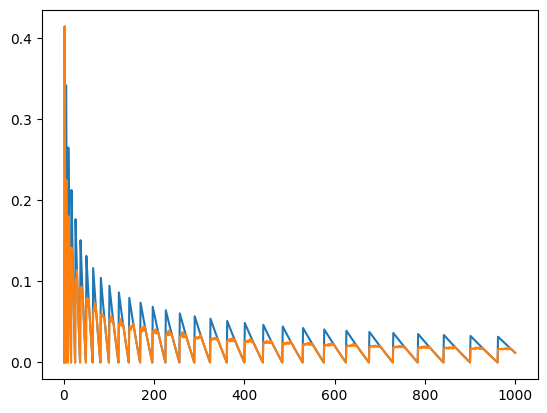

In [204]:
# Scores before and after
sqnum = [best[i]['n_squares'] for i in best]
plt.plot(sqnum, scores_base)
plt.plot(sqnum, scores_chk1)
plt.show()

In [264]:
import pandas as pd

submission = (pd.DataFrame([[best[i]['n_squares'], sqnum, sq[1], sq[0], sq[2]]
                            for i in best
                            for sqnum,sq in enumerate(get_squares(best[i]))],
                           columns=['n', 'square_id', 'x', 'y', 'angle'])
              .reset_index(names='id'))
submission.to_csv('../data/submission.csv', sep=',', index=False)

1 1


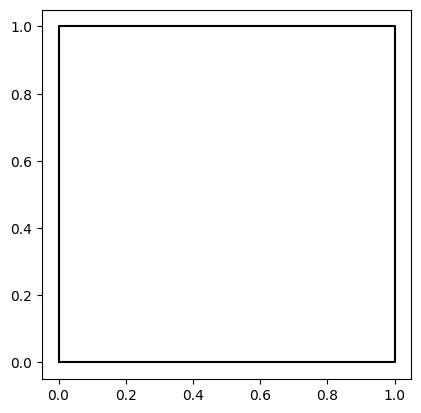


2 2


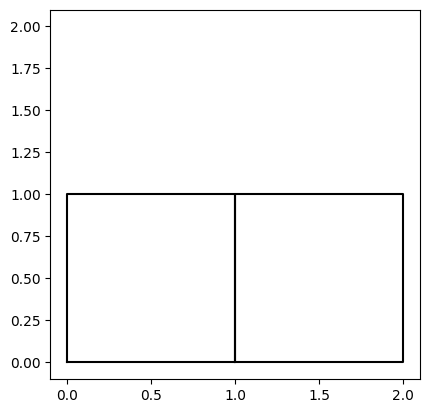


3 2


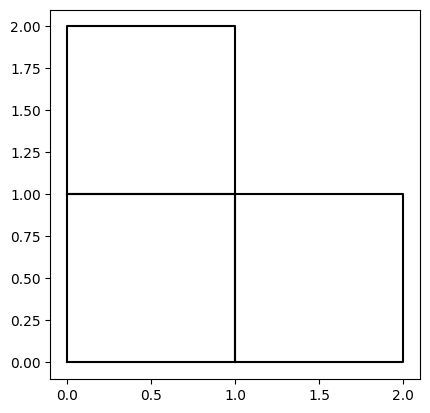


4 2


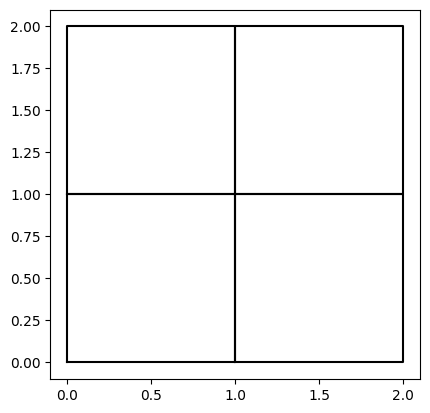


5 2.7071067811865475


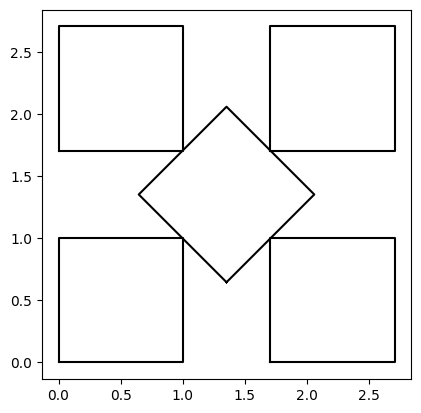


6 3


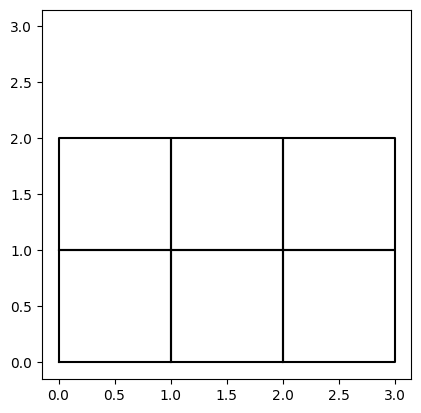


7 3


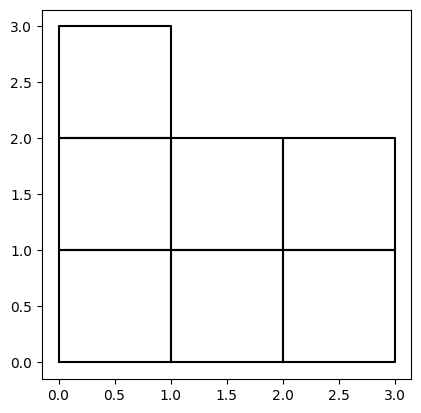


8 3


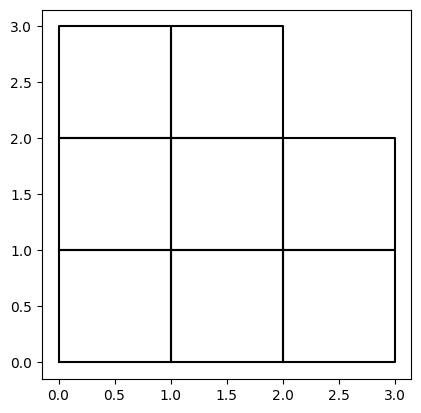


9 3


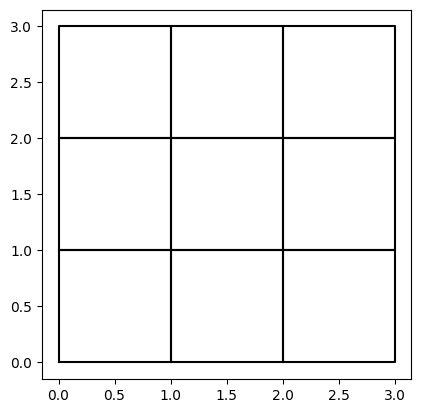


10 3.7071067811865475


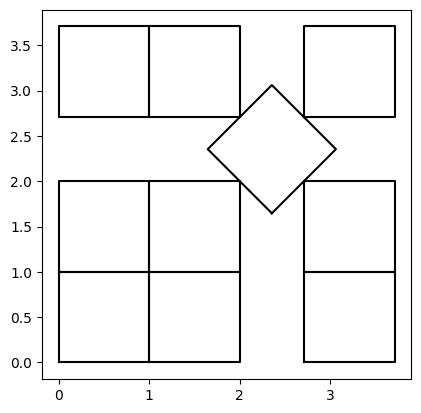


11 3.914213562373095


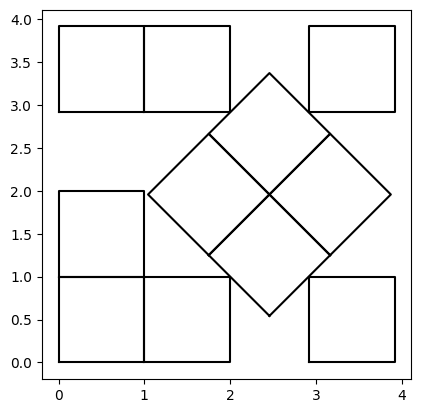


12 4


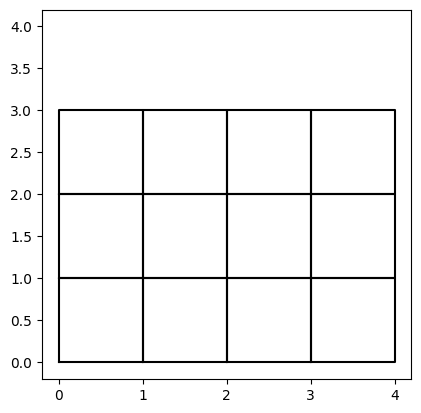


13 4


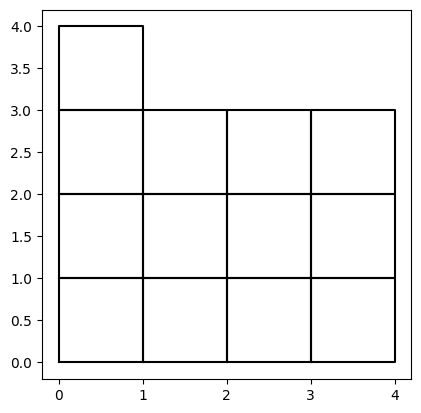


14 4


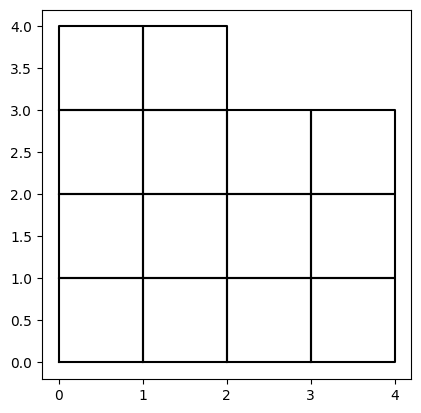


15 4


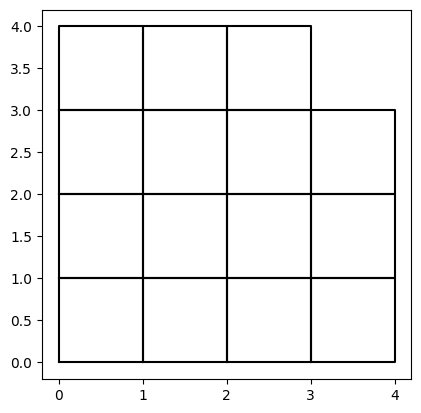


16 4


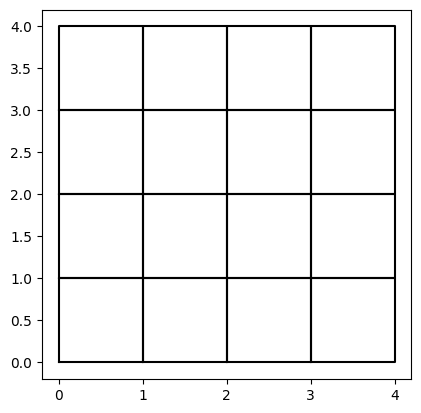


17 4.707106781186548


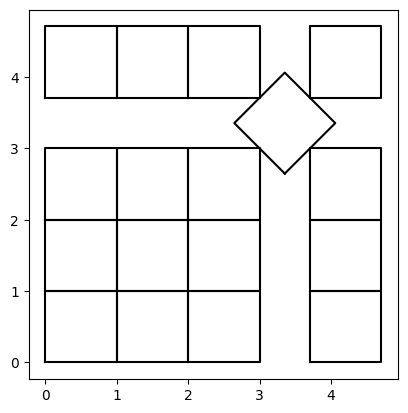


18 4.82842712474619


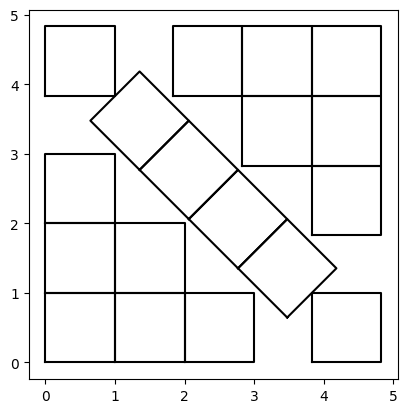


19 4.914213562373096


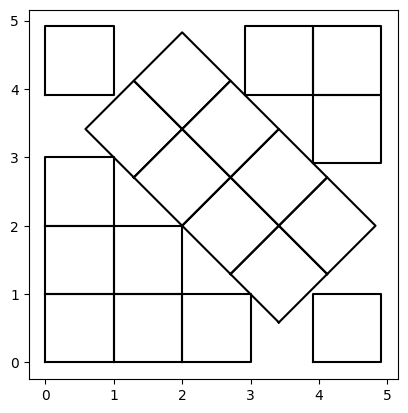


20 5


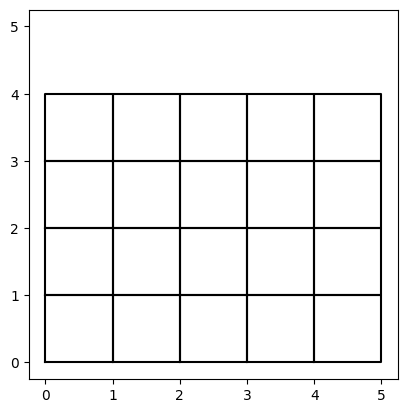


21 5


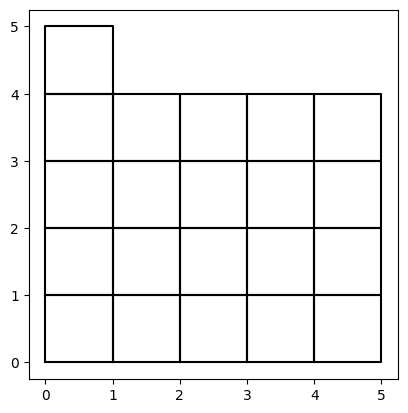


22 5


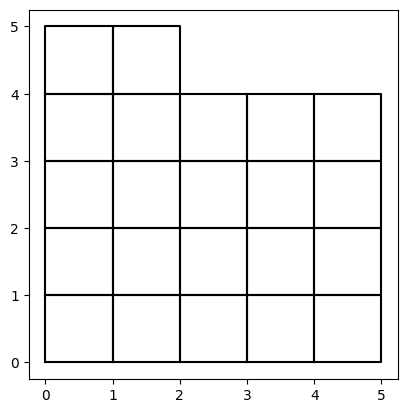


23 5


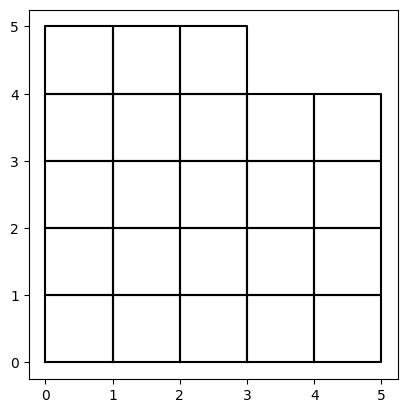


24 5


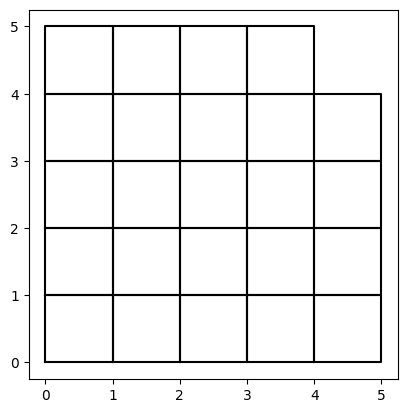


25 5


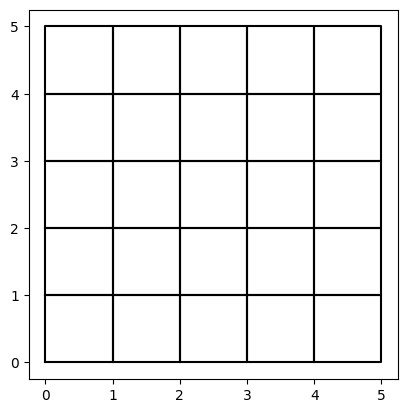


26 5.621320343559643


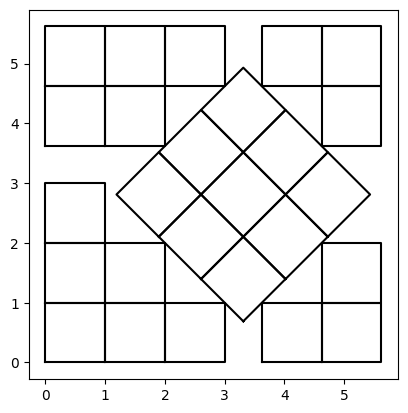


27 5.707106781186548


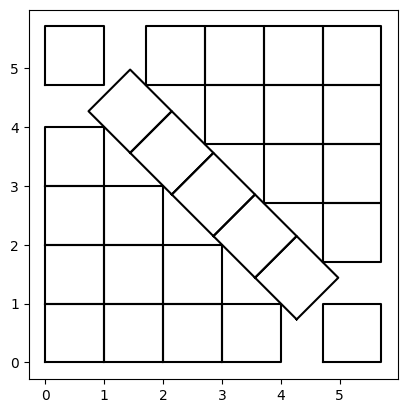


28 5.82842712474619


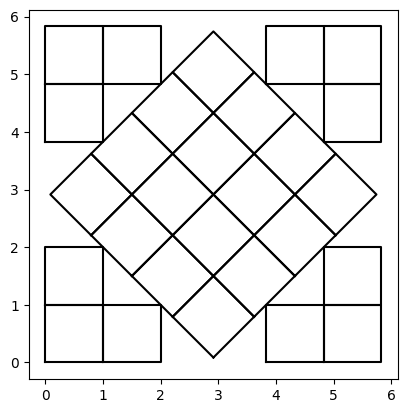


29 6


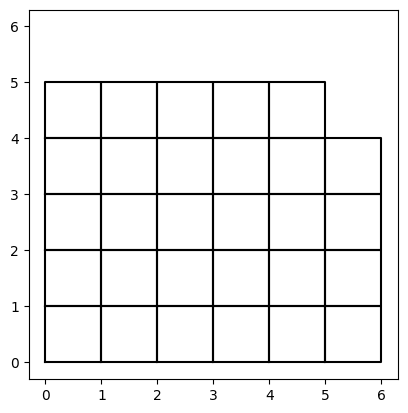


30 6


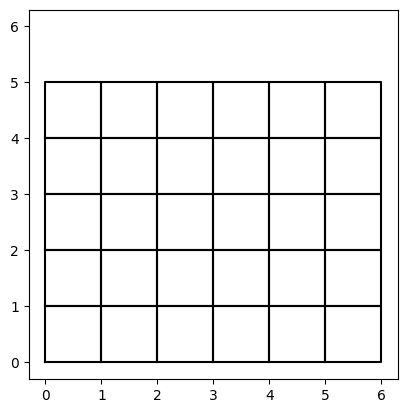


31 6


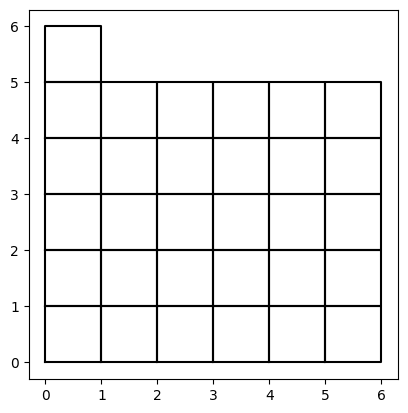


32 6


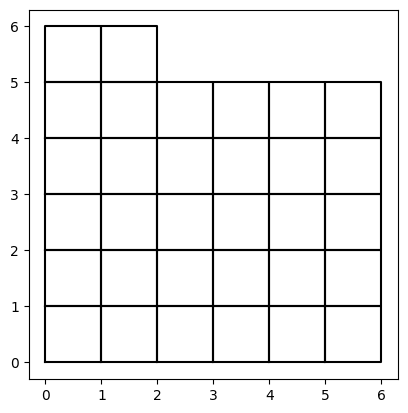


33 6


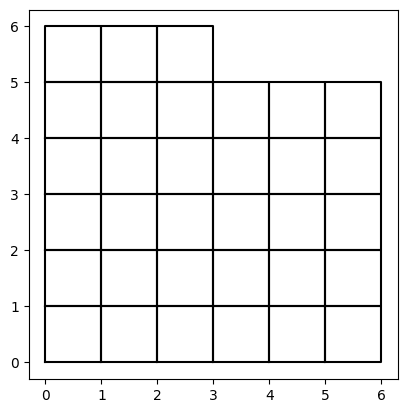


34 6


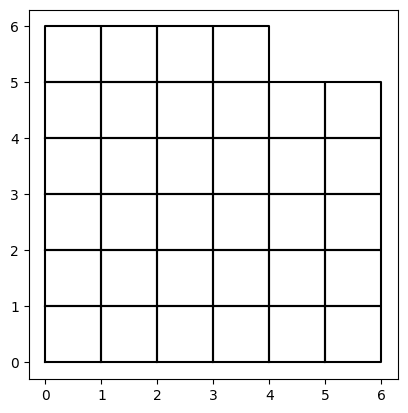


35 6


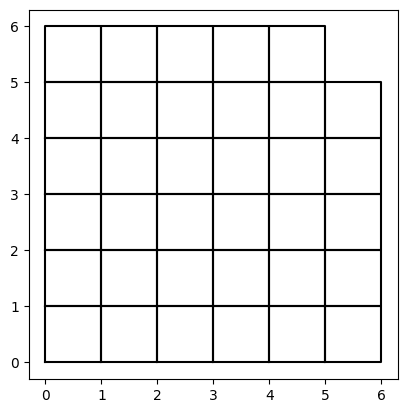


36 6


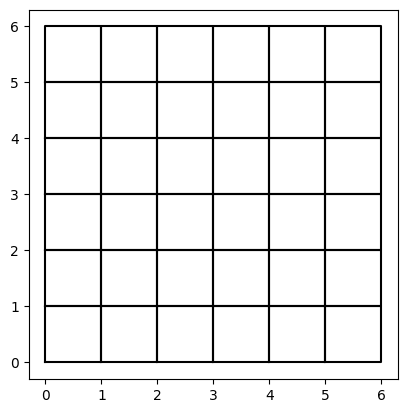


37 6.621320343559643


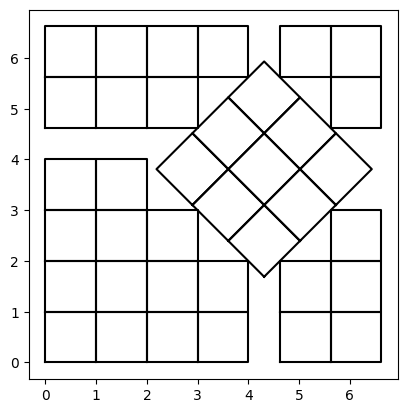


38 6.707106781186548


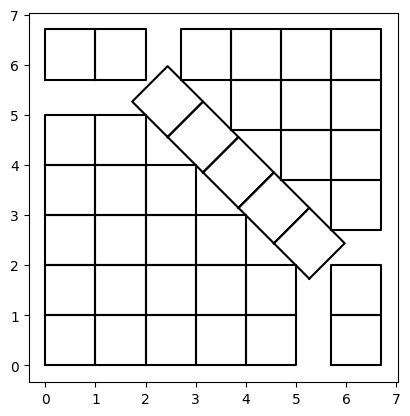


39 6.82842712474619


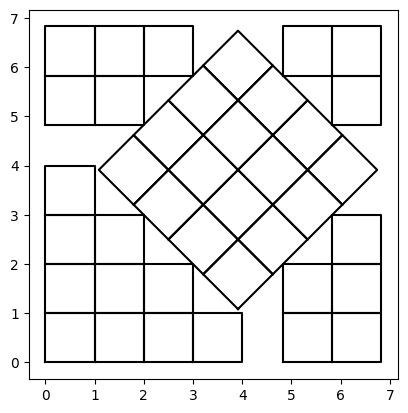


40 6.82842712474619


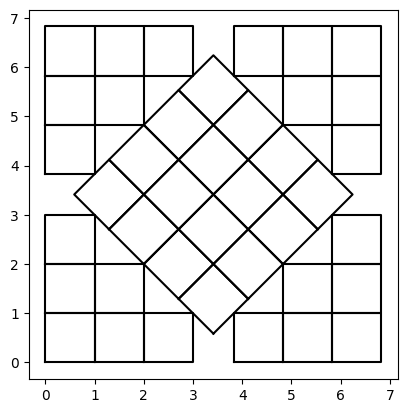


41 6.949747468305833


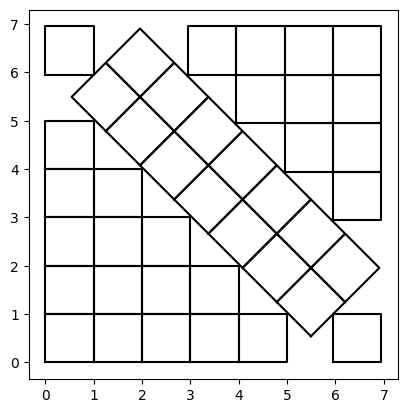


42 7


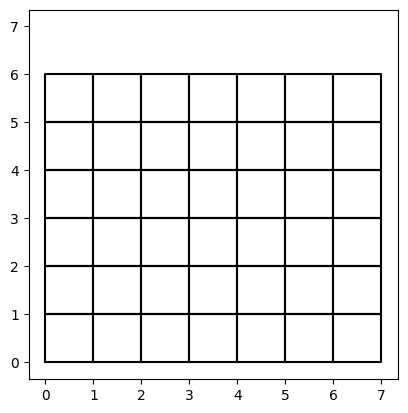


43 7


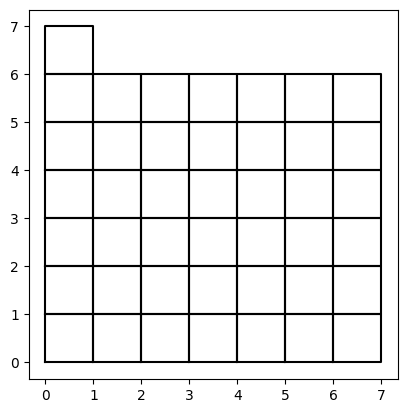


44 7


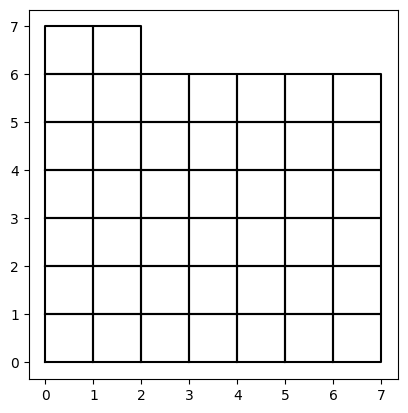


45 7


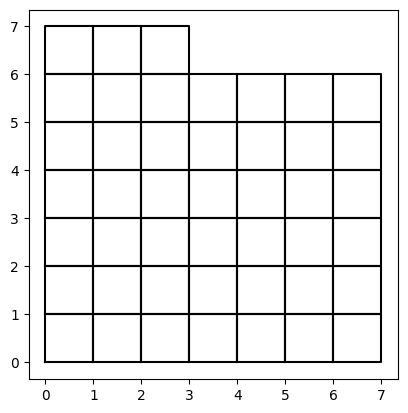


46 7


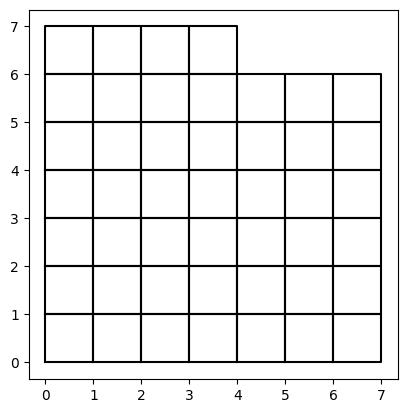


47 7


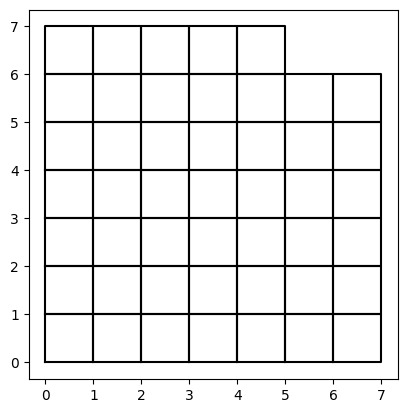


48 7


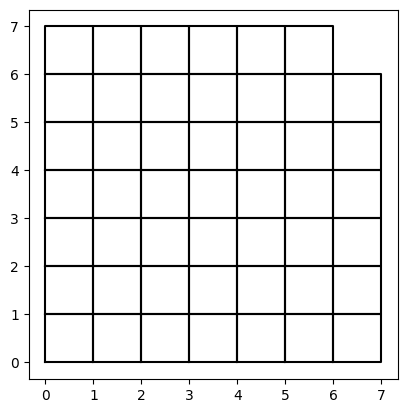


49 7


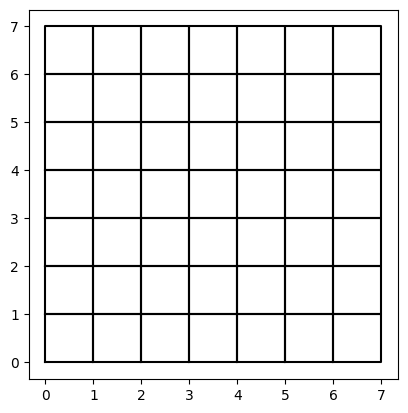


50 7.621320343559643


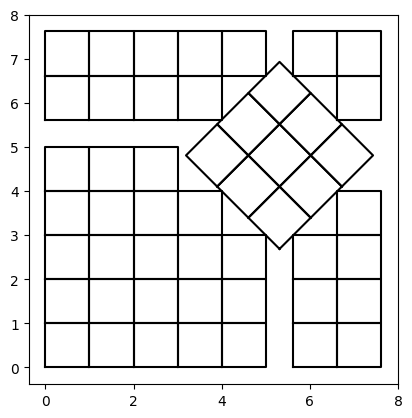

In [265]:
for i in range(1,51):
    print(best[i]['n_squares'], best[i]['box_size'])
    show_squares(get_squares(best[i]))
    print()